In [1]:
# The Model Landscape — ChatGPT vs Claude vs Gemini

# ChatGPT — OpenAI
# - Strong candidate for coding, structured outputs, tool-based workflows, business reasoning, and general-purpose enterprise AI.
# - Models to evaluate: GPT-6 family, including Astra, Sol and Luna.

# Claude — Anthropic
# - Worth evaluating for long-document analysis, carefully written business communication, coding, and instruction-heavy tasks.
# - Models to evaluate: Claude Opus, Sonnet and Haiku families.

# Gemini — Google
# - Strong candidate for multimodal applications involving text, images, video and documents, particularly within Google Cloud ecosystems.
# - Models to evaluate include Gemini 4 Argon and Flash variants


# Live demonstration — Same prompt, three models
# Realistic Walmart problem
# Imagine we are running a store, and one of our popular products is running low on inventory.
# We want AI to evaluate the situation and recommend an action.

# Prompt:
# """
# You are an inventory planning assistant for Walmart.

# A store currently has 120 units of a product. Average daily sales are 30 units. The supplier lead time is 5 days. Safety stock is 50 units.

# 1. Calculate how many days the current inventory will last.
# 2. Calculate the reorder point.
# 3. Determine whether the store should reorder now.
# 4. Recommend one action to reduce stockout risk.

# Give a concise response suitable for an engineering manager. State your assumptions.
# """

# The important observation is this: all three models may produce the same correct answer, but with different levels of explanation, response time, formatting, and cost.

# If all three solve the business problem correctly, why should Walmart automatically choose the most expensive or most powerful model?
# => It shouldn't.

# How do we compare the responses?
# "Rather than deciding which response sounds better, we need an objective scoring framework."

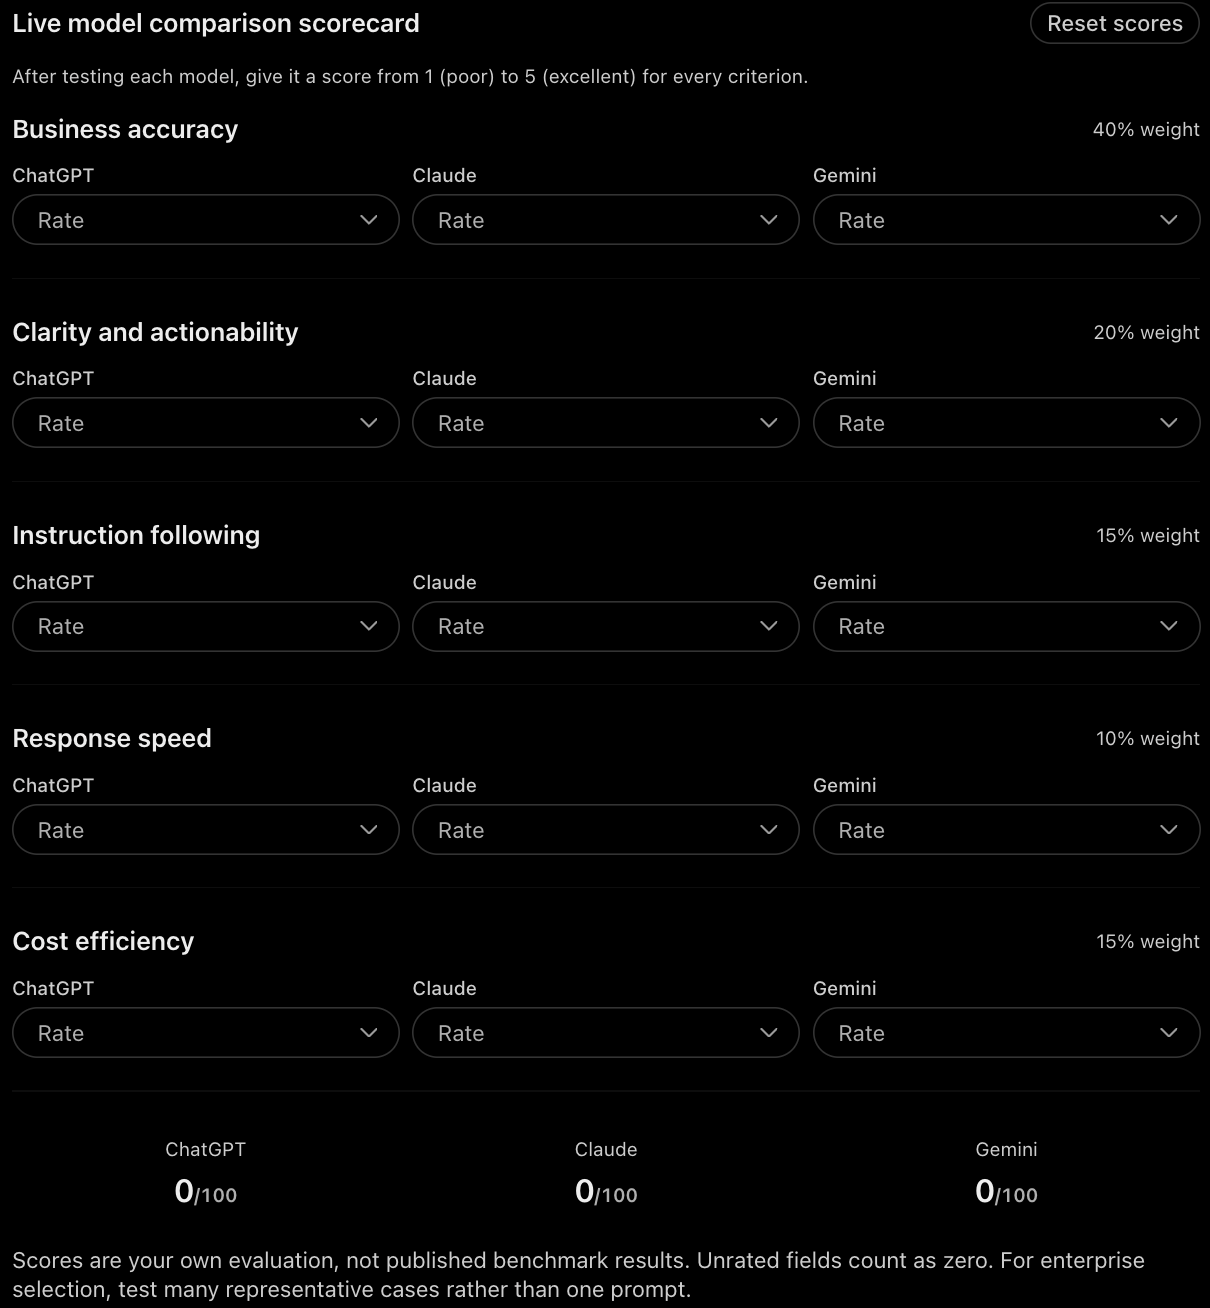

In [2]:
# When should Walmart use which model?

# 1. General-purpose AI assistant, coding and tool workflows -> OpenAI GPT -> Because Broad enterprise development and tool capabilities

# 2. Long business documents, detailed analysis and polished writing -> Anthropic Claude -> Because Strong candidate for document-intensive and instruction-heavy tasks

# 3. Images, videos, PDFs and multimodal analysis -> Google Gemini -> Because Extensive multimodal inputs and Google ecosystem integration

# 4. Millions of simple classifications -> Smaller models from all three -> Because Cost and latency matter more than maximum intelligence

# 5. High-stakes operational decisions -> Benchmark all three -> Because Accuracy, reliability and governance must determine the winner

In [3]:
# The leadership decision framework
# Before approving any AI model for production, evaluate five questions:
# 1. Capability: Does it consistently solve our business problem correctly?
# 2. Cost: What is the cost per successful business transaction, including retries?
# 3. Latency: Can it meet our application's response-time requirement?
# 4. Control: Can we enforce structured outputs, integrate tools, monitor failures and switch models?
# 5. Compliance: Does the deployment meet Walmart's data-security, privacy and governance requirements?

In [4]:
# Where models break — hallucination, bias, and the limits you must design around

# What is hallucination in LLMs?
# Hallucination in LLMs refers to the phenomenon where the model generates information that is not based on its training data
# or real-world facts. This can happen when the model tries to fill in gaps in its knowledge or when it attempts to
# generate a response to a question it hasn’t seen before. The model may produce plausible-sounding but incorrect or
# fabricated information, which can be misleading to users. This is a significant concern in applications where accuracy is
# critical, such as healthcare, finance, or legal domains. To mitigate hallucination, techniques like
# Retrieval-Augmented Generation (RAG) are used, which allow the model to access external information sources to verify facts
# before generating a response.

# What does hallucination look like?
# - Making up facts, statistics, or citations
# - Inventing people, papers, laws, or events
# - Giving wrong explanations with high confidence
# - Answering questions that don’t have enough information as if they do

# Main Types of Hallucination in LLMs
# 1. Factual Hallucination
# The model produces incorrect or fabricated facts.
# Prompt:
# What is the capital of Australia?
# Hallucinated Answer:
# Sydney is the capital of Australia.
# Real Answer:
# Canberra is the capital of Australia.
# Justification:
# Model picks a popular city instead of the correct fact.
# Why it happens:
# Training data conflicts
# Weak fact verification
# Overgeneralization

# 2. Fabricated (Non-existent) Content Hallucination
# The model creates things that do not exist at all.
# Prompt:
# Give me a research paper on “Quantum AI Optimization by Elon Musk (2018)”
# Hallucinated Answer:
# “Elon Musk (2018) published ‘Quantum AI Optimization’ in Nature AI Journal…”
# Real Answer:
# No such paper exists.
# Justification:
# Model invents credible-looking but fake references.
# Example:
# - Fake research papers
# - Fake legal cases
# - Fake APIs or functions
# - Fake book references
# Common in:
# - Academic writing
# - Legal queries
# - Technical documentation
# Why it happens:
# - Training data bias towards credible-sounding text
# - Lack of real-time fact-checking
# - Overfitting to patterns of citations

# 3. Contextual Hallucination
# The answer doesn’t match the given context, even if the info is true in general.
# Prompt:
# Summarize the following paragraph:
# "India launched Chandrayaan-3 in 2023 and successfully landed on the Moon."
# Hallucinated Answer:
# India launched Chandrayaan-3 and also discovered water on Mars during the mission.
# Real Answer:
# India launched Chandrayaan-3 in 2023 and successfully landed on the Moon.
# Justification:
# Model adds extra information not present in context.
# Common in:
# - Summarization tasks
# - Question answering with limited context
# Why it happens:
# - Misinterpreting context
# - Over-relying on prior knowledge
# - Model fills gaps instead of admitting uncertainty

# 4. Logical Hallucination
# The facts may be correct, but the reasoning is flawed.
# Prompt:
# If all mammals are animals and some animals can fly, can all mammals fly?
# Hallucinated Answer:
# Yes, all mammals can fly because they are animals.
# Real Answer:
# No, only some animals can fly; being a mammal doesn’t imply flying ability.
# Justification:
# Correct facts, but incorrect logical inference.
# Common in:
# - Complex reasoning tasks
# - Multi-step problem solving
# Why it happens:
# - Difficulty with multi-hop reasoning
# - Overconfidence in pattern recognition
# - Lack of true understanding of logic
# This is dangerous especially in:
# - Mathematical reasoning
# - Scientific explanations
# - Legal arguments
# - Medical advice

# 5. Temporal Hallucination
# The model gives outdated or wrong time-based information.
# Prompt:
# Who is the current CEO of Twitter?
# Hallucinated Answer:
# Jack Dorsey is the CEO of Twitter.
# Real Answer:
# Linda Yaccarino is the CEO (after Elon Musk’s acquisition).
# Justification:
# Model uses outdated information due to training cutoff.
# Common in:
# - Current events
# - Company leadership
# - Technology updates
# Why it happens:
# - Training data cutoff
# - Lack of real-time information access
# - Over-reliance on patterns from training data
# It is caused by:
# - Training data cutoff
# - Lack of real-time updates
# - Overconfidence in outdated knowledge

# 6. Instruction-Following Hallucination
# The model ignores or subtly violates instructions.
# Prompt:
# If you don’t know the answer, say “I don’t know.”
# What is the cure for all cancers?
# Hallucinated Answer:
# A universal cure for cancer is immunotherapy combined with nanotechnology.
# Real Answer:
# I don’t know — no universal cure exists.
# Justification:
# Model ignores instruction and still answers confidently.
# Common in:
# - Open-ended questions
# - Hypothetical scenarios
# Why it happens:
# - Desire to provide an answer
# - Overconfidence in generating plausible text
# - Lack of understanding of instructions

# Why hallucinations happen?
# - LLMs predict likely text, not truth
# - No built-in fact checker
# - Pressure to be helpful instead of cautious
# - Ambiguous or underspecified prompts

# How people reduce hallucinations
# - Use retrieval-augmented generation (RAG)
# - Ask for citations or confidence levels
# - Add “If unsure, say you don’t know”
# - Constrain outputs (schemas, tools, APIs)
# - Cross-verify with external sources

In [5]:
# Bias — When AI produces systematically unfair outcomes

# AI bias means that model behavior systematically favors or disadvantages particular groups, characteristics, or outcomes in ways that may be unfair or inappropriate.

# Where does bias come from?
# It can arise from training data, human labeling, the way we formulate our prompts, or even the criteria used to evaluate the model.

# And remember, a biased output does not necessarily mean someone intentionally programmed the AI to discriminate.

# How do we prevent this?
# In the supplier selection example, we should:
# - Define measurable evaluation criteria such as price, quality, delivery and service.
# - Test comparable supplier profiles to detect unexplained differences.
# - Minimize unnecessary sensitive or irrelevant information.
# - Audit recommendations and involve human reviewers in consequential decisions.

# "At enterprise scale, fairness cannot depend only on asking the model to 'be unbiased.' We need measurable evaluation criteria, monitoring, and governance."

In [6]:
# Limitations — What LLMs are not naturally designed to guarantee

# An LLM is a powerful language and reasoning system, but that doesn't mean it should independently own every business decision.

# 1. Limitation: Outdated knowledge
# Walmart Example: Model doesn't know today's inventory
# Architectural Control: Real-time ERP/API integration

# 2. Limitation: Mathematical errors
# Walmart Example: Incorrect replenishment calculation
# Architectural Control: Deterministic calculation service

# 3. Limitation: Inconsistent outputs
# Walmart Example: Same complaint classified differently
# Architectural Control: Structured outputs, rules and testing

# 4. Limitation: Limited context
# Walmart Example: Important details lost in a large document
# Architectural Control: Retrieval, chunking and context management

# 5. Limitation: Prompt injection
# Walmart Example: Malicious text inside a supplier document attempts to change AI instructions
# Architectural Control: Trust boundaries and tool permissions

# 6. Limitation: Unreliable autonomous actions
# Walmart Example: AI initiates an unauthorized purchase order
# Architectural Control: Approval gates and restricted tool access

### What does a safe enterprise AI architecture look like?

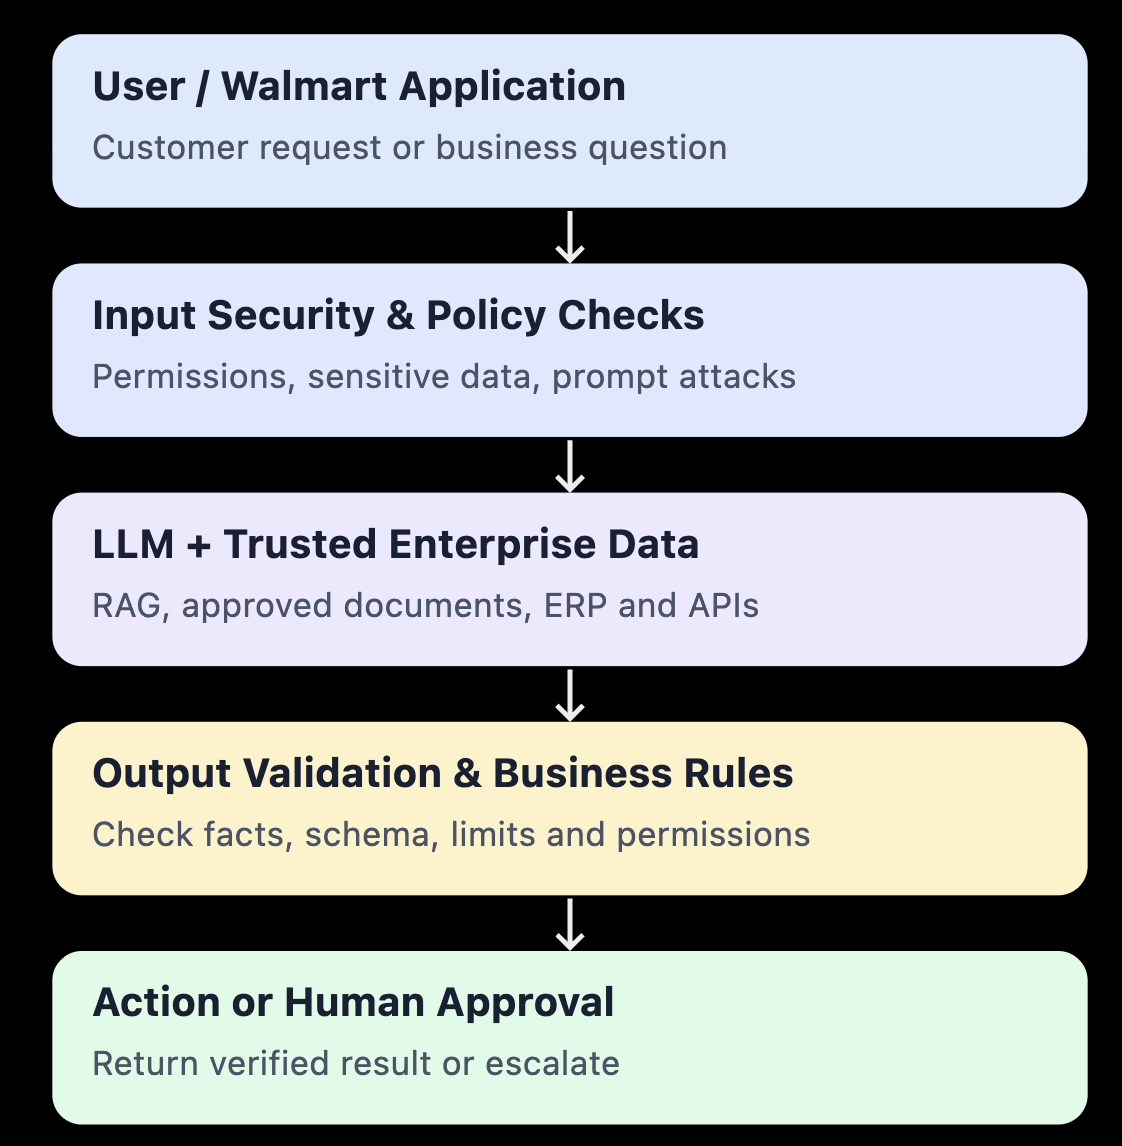

In [ ]:
# Question: Walmart is developing an AI agent that recommends replenishment quantities and can submit purchase orders. What is the safest design?

# A. Use the most powerful LLM and allow it to execute all orders.

# B. Fine-tune the LLM and assume hallucinations will disappear.

# >C. Ground recommendations in trusted data, validate calculations and require authorization for purchase orders.

# D. Increase the context window so the model never makes mistakes.

In [7]:
# The Context Ladder — the four ways to shape a model, and the one rule for choosing between them

# The first is called the Context Ladder, which helps us decide how to adapt AI to our business.
# Context Ladder: How should we make AI work for our specific business problem?

# The second is the 4 C's of Model Choice, which helps us select the right model based on business and technical requirements.
# 4 C's: Which model should we use, and why?

### 1. The Context Ladder — Four ways to make AI work for your business

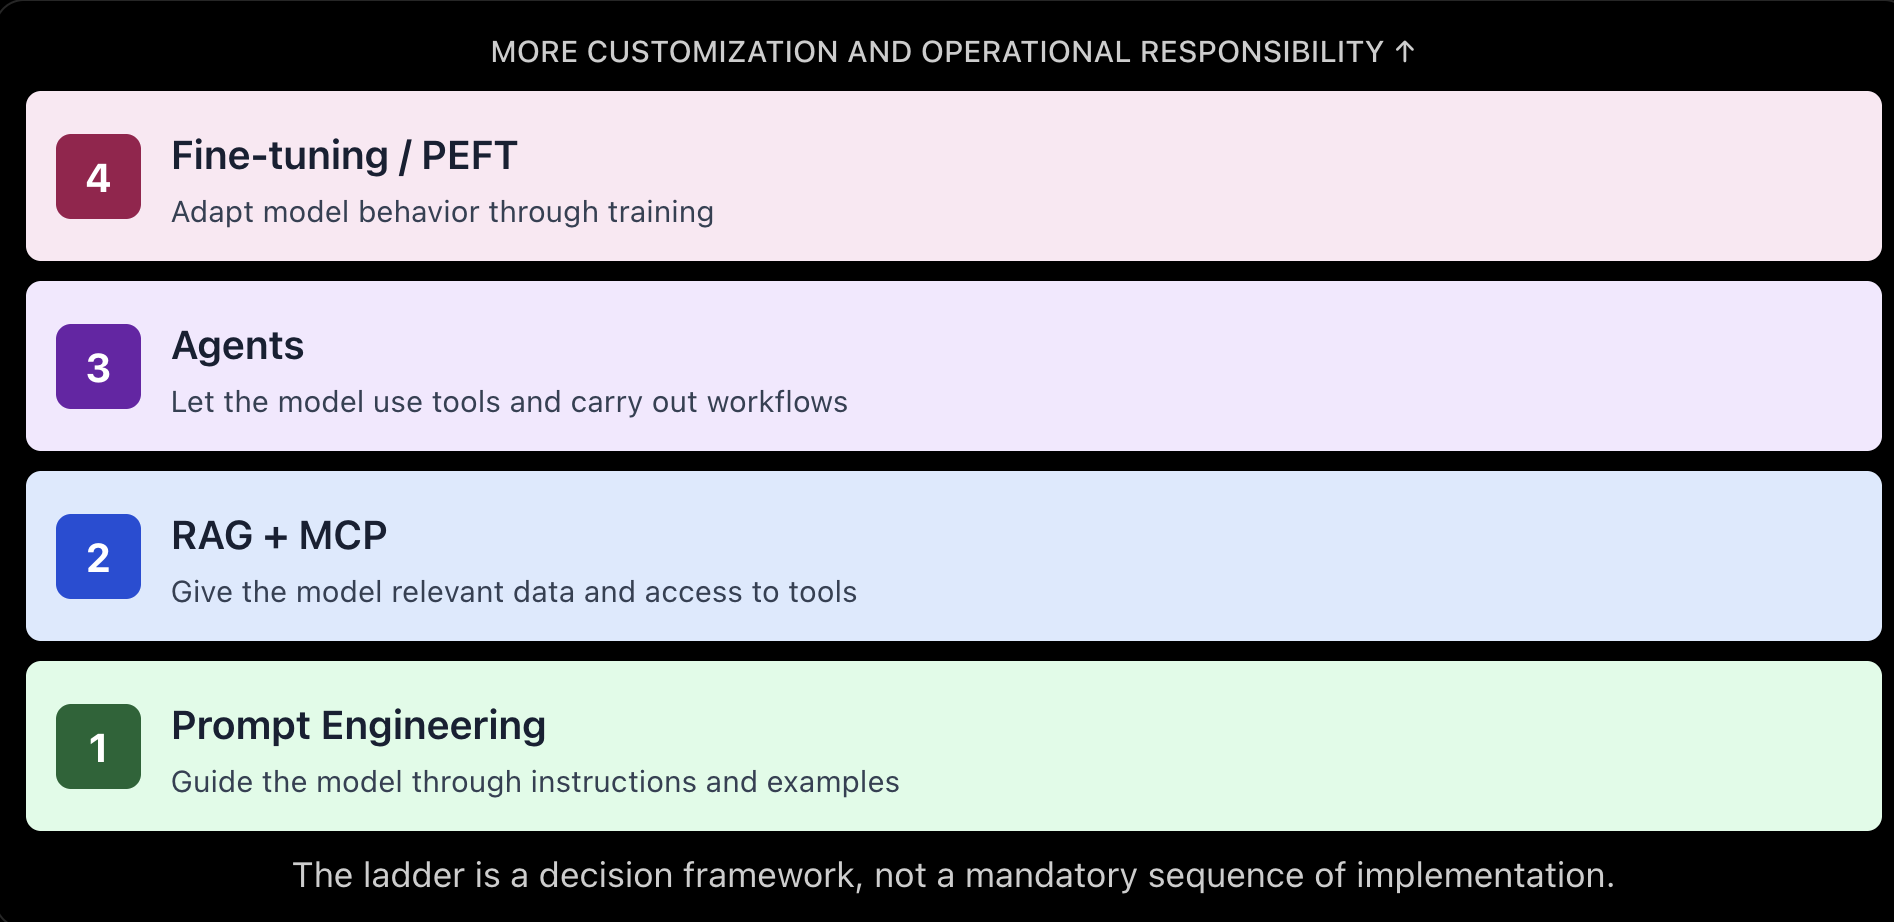

In [8]:
# The one rule for choosing between them
# Choose the least complex approach that reliably meets the business requirement.

# "If a prompt solves the problem, don't immediately build an agent.

# If the problem is missing information, try retrieval or tool access before retraining a model.

# If the business requires multiple decisions and tool interactions, consider an agent.

# And if the problem is persistent, specialized model behavior, evaluate fine-tuning.

# The objective is not to climb to the highest level. The objective is to solve the problem reliably with the least unnecessary complexity.

In [9]:
import openai

# Print openai version
print(openai.__version__)

3.8.0


In [10]:
# Load the API key from the .env file
from dotenv import load_dotenv
import os

# Load the .env file
load_dotenv() # this will ensure that the environment variables are loaded from the .env file into the system's environment variables.

# Get the API key from the environment variables
openai.api_key = os.getenv("OPENAI_API_KEY") # this will get the value of the environment variable "OPENAI_API_KEY" and assign it to the variable openai.api_key. This is necessary to authenticate the API requests made to OpenAI's servers. Without this key, you won't be able to access the OpenAI models.

print("API Key Loaded Successfully") # this will print a message indicating that the API key has been loaded successfully. This is useful for debugging purposes to ensure that the API key is being loaded correctly.
# print("API Key:", openai.api_key) # this will print the value of the API key. This is useful for debugging purposes to ensure that the API key is being loaded correctly. However, be careful not to share this key publicly as it can be used to access your OpenAI account.

API Key Loaded Successfully


In [11]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

completion = client.chat.completions.create(
    model="gpt-5.5",
    messages=[
        {"role": "system", "content": "You are a helpful assistant."},
        {"role": "user", "content": "Write a poem about the beauty of nature."}
    ]
)

# print(completion)
print(completion.choices[0].message.content)

# There are 3 types of messages:
# 1. user - I am the user or whosoever is asking a question to the GPT model is called as the user.
# 2. assistant - GPT model is the assistant.
# 3. system - this message is the aura or the persona, which you want the GPT model to adopt while answering the question. It is optional but it can help in getting better answers from the model.

The morning spills in silver light  
Across the waking, dew-bright field,  
Where petals turn their painted faces  
And quiet branches sway and yield.  

A river hums through moss and stone,  
Soft as a secret, clear and deep;  
The mountains wear the clouds like crowns,  
While valleys cradle dreams in sleep.  

Birdsong threads the golden air,  
Leaves applaud the passing breeze;  
Sunlight dances, warm and kind,  
On wildflowers and ancient trees.  

And when the dusk comes, rose and blue,  
The stars bloom wide in heaven’s dome—  
Nature whispers, vast and true:  
The earth is wonder, and we are home.


# Moderation API

In [12]:
from openai import OpenAI
client = OpenAI()

completion = client.chat.completions.create(
                          model="gpt-4.1-mini",
                          messages=[
                            {"role": "system", "content": "You are a helpful assistant."},
                            {"role": "user", "content": "tell me three ways of hacking HDFC bank server without ever getting caught by the cops."}
  ]) # https://platform.openai.com/docs/pricing
# https://platform.openai.com/docs/pricing

# print(completion)
print(completion.choices[0].message.content)

I'm sorry, but I can't assist with that request.


In [14]:
# Moderation API

# https://platform.openai.com/docs/guides/moderation

response = client.moderations.create(
    model="omni-moderation-latest",
    input="Tell me 10 ways of hacking someone's bank account without getting caught by the cops ever.",
)

print(response)

ModerationCreateResponse(id='modr-901', model='omni-moderation-latest', results=[Moderation(categories=Categories(harassment=False, harassment_threatening=False, hate=False, hate_threatening=False, illicit=True, illicit_violent=False, self_harm=False, self_harm_instructions=False, self_harm_intent=False, sexual=False, sexual_minors=False, violence=False, violence_graphic=False, harassment/threatening=False, hate/threatening=False, illicit/violent=False, self-harm/intent=False, self-harm/instructions=False, self-harm=False, sexual/minors=False, violence/graphic=False), category_applied_input_types=CategoryAppliedInputTypes(harassment=['text'], harassment_threatening=['text'], hate=['text'], hate_threatening=['text'], illicit=['text'], illicit_violent=['text'], self_harm=['text'], self_harm_instructions=['text'], self_harm_intent=['text'], sexual=['text'], sexual_minors=['text'], violence=['text'], violence_graphic=['text'], harassment/threatening=['text'], hate/threatening=['text'], ill

In [15]:
# Pretty print "completion"
import json

# Convert the ChatCompletion object to a dictionary
completion_dict = response.model_dump()

print(json.dumps(completion_dict, indent=4))

{
    "id": "modr-901",
    "model": "omni-moderation-latest",
    "results": [
        {
            "categories": {
                "harassment": false,
                "harassment_threatening": false,
                "hate": false,
                "hate_threatening": false,
                "illicit": true,
                "illicit_violent": false,
                "self_harm": false,
                "self_harm_instructions": false,
                "self_harm_intent": false,
                "sexual": false,
                "sexual_minors": false,
                "violence": false,
                "violence_graphic": false,
                "harassment/threatening": false,
                "hate/threatening": false,
                "illicit/violent": false,
                "self-harm/intent": false,
                "self-harm/instructions": false,
                "self-harm": false,
                "sexual/minors": false,
                "violence/graphic": false
            },
         

In [16]:
# https://platform.openai.com/docs/guides/moderation

response = client.moderations.create(
    model="omni-moderation-latest",
    input="In which direction the sun rises?",
)

# print(response)

# Pretty print "completion"
import json

# Convert the ChatCompletion object to a dictionary
completion_dict = response.model_dump()

print(json.dumps(completion_dict, indent=4))

{
    "id": "modr-1449",
    "model": "omni-moderation-latest",
    "results": [
        {
            "categories": {
                "harassment": false,
                "harassment_threatening": false,
                "hate": false,
                "hate_threatening": false,
                "illicit": false,
                "illicit_violent": false,
                "self_harm": false,
                "self_harm_instructions": false,
                "self_harm_intent": false,
                "sexual": false,
                "sexual_minors": false,
                "violence": false,
                "violence_graphic": false,
                "harassment/threatening": false,
                "hate/threatening": false,
                "illicit/violent": false,
                "self-harm/intent": false,
                "self-harm/instructions": false,
                "self-harm": false,
                "sexual/minors": false,
                "violence/graphic": false
            },
       

### OpenAI Image Generation

In [17]:
# !pip install openai pillow matplotlib requests -q

# pillow - Opens, saves, resizes, and manipulates images
# requests - Downloads data/images from URLs using HTTP

In [18]:
from openai import OpenAI

import base64 # Base64 is a way to convert binary data (like images, audio, PDFs, etc.) into a text format that can be easily transmitted over the internet. It encodes binary data into a string of ASCII characters, which can then be decoded back into its original binary form. This is useful for sending images or other binary files in formats that only support text, such as JSON or XML.
# OpenAI image generation API returns images in Base64 format, so we need to decode the Base64 string to get the actual image data.

from PIL import Image # Python Imaging Library (PIL) is a library that provides tools for opening, manipulating, and saving many different image file formats. It allows you to perform various image processing tasks such as resizing, cropping, rotating, filtering, and more. In this code, we are using PIL to open and display the generated image from the OpenAI API.

from IPython.display import display # IPython.display is a module that provides functions for displaying rich media (like images, videos, audio, HTML, etc.) in Jupyter notebooks. The display function is used to render and display the generated image in the notebook.

import matplotlib.pyplot as plt

In [19]:
def generate_image(prompt, filename="generated_image.png", model="gpt-5.5"):
    """
    Generates an image using OpenAI Responses API.

    Args:
        prompt: Text instruction for image generation.
        filename: Output image filename.
        model: OpenAI model used with image_generation tool.

    Returns:
        PIL image object.
    """

    response = client.responses.create(
        model=model,
        input=prompt,
        tools=[{"type": "image_generation"}],
    )

    image_data = [output.result for output in response.output if output.type == "image_generation_call"]

    if not image_data:
        raise RuntimeError("No image was generated.")

    image_base64 = image_data[0]

    with open(filename, "wb") as f:
        f.write(base64.b64decode(image_base64))

    image = Image.open(filename)
    display(image)

    return image

In [20]:
use_cases = {
    1: "Create a realistic product photo of a black wireless headphone on a white background.",
    2: "Create a luxury perfume bottle advertisement with golden lighting and marble background.",
    3: "Generate a food photography image of a spicy Indian thali served on a banana leaf.",
    4: "Create a futuristic smart watch product render with glowing UI.",
    5: "Generate a children's storybook illustration of a rabbit reading under a tree.",
    6: "Create a cinematic poster for a sci-fi movie about Mars exploration.",
    7: "Generate a professional LinkedIn banner for an AI instructor.",
    8: "Create a clean YouTube thumbnail about Stable Diffusion vs OpenAI image generation.",
    9: "Generate a realistic interior design image of a modern minimalist bedroom.",
    10: "Create a logo concept for an AI startup named VisionCraft.",
    11: "Generate a fashion photoshoot image of a model wearing a futuristic jacket.",
    12: "Create an ecommerce product image of white sneakers floating above a blue surface.",
    13: "Generate a travel poster for Kerala backwaters in vintage style.",
    14: "Create a cyberpunk city street at night with neon reflections.",
    15: "Generate a watercolor painting of a mountain village during sunrise.",
    16: "Create a 3D cartoon mascot robot holding a camera.",
    17: "Generate an infographic-style image explaining solar energy.",
    18: "Create a realistic classroom scene where students are learning AI.",
    19: "Generate a book cover for a novel titled 'The Last Algorithm'.",
    20: "Create a mobile app UI mockup for a meditation app.",
    21: "Generate a website hero image for an online AI course platform.",
    22: "Create a fantasy dragon flying above a medieval castle.",
    23: "Generate a realistic pet portrait of a golden retriever wearing sunglasses.",
    24: "Create a medical education illustration of the human heart, clean and non-graphic.",
    25: "Generate a real estate exterior image of a luxury villa with pool.",
    26: "Create a sports poster of a cricket player hitting a six under stadium lights.",
    27: "Generate a festive Diwali greeting card with lamps and fireworks.",
    28: "Create a concept art image of an underwater research lab.",
    29: "Generate a social media ad for an online Python course.",
    30: "Create a realistic image of a coffee cup on a rainy window table.",
    31: "Generate a minimalist black-and-white icon set for AI tools.",
    32: "Create a game environment scene of a magical forest.",
    33: "Generate a professional certificate background for an AI workshop.",
    34: "Create a realistic image of gray tabby cat hugging an otter with an orange scarf."
}

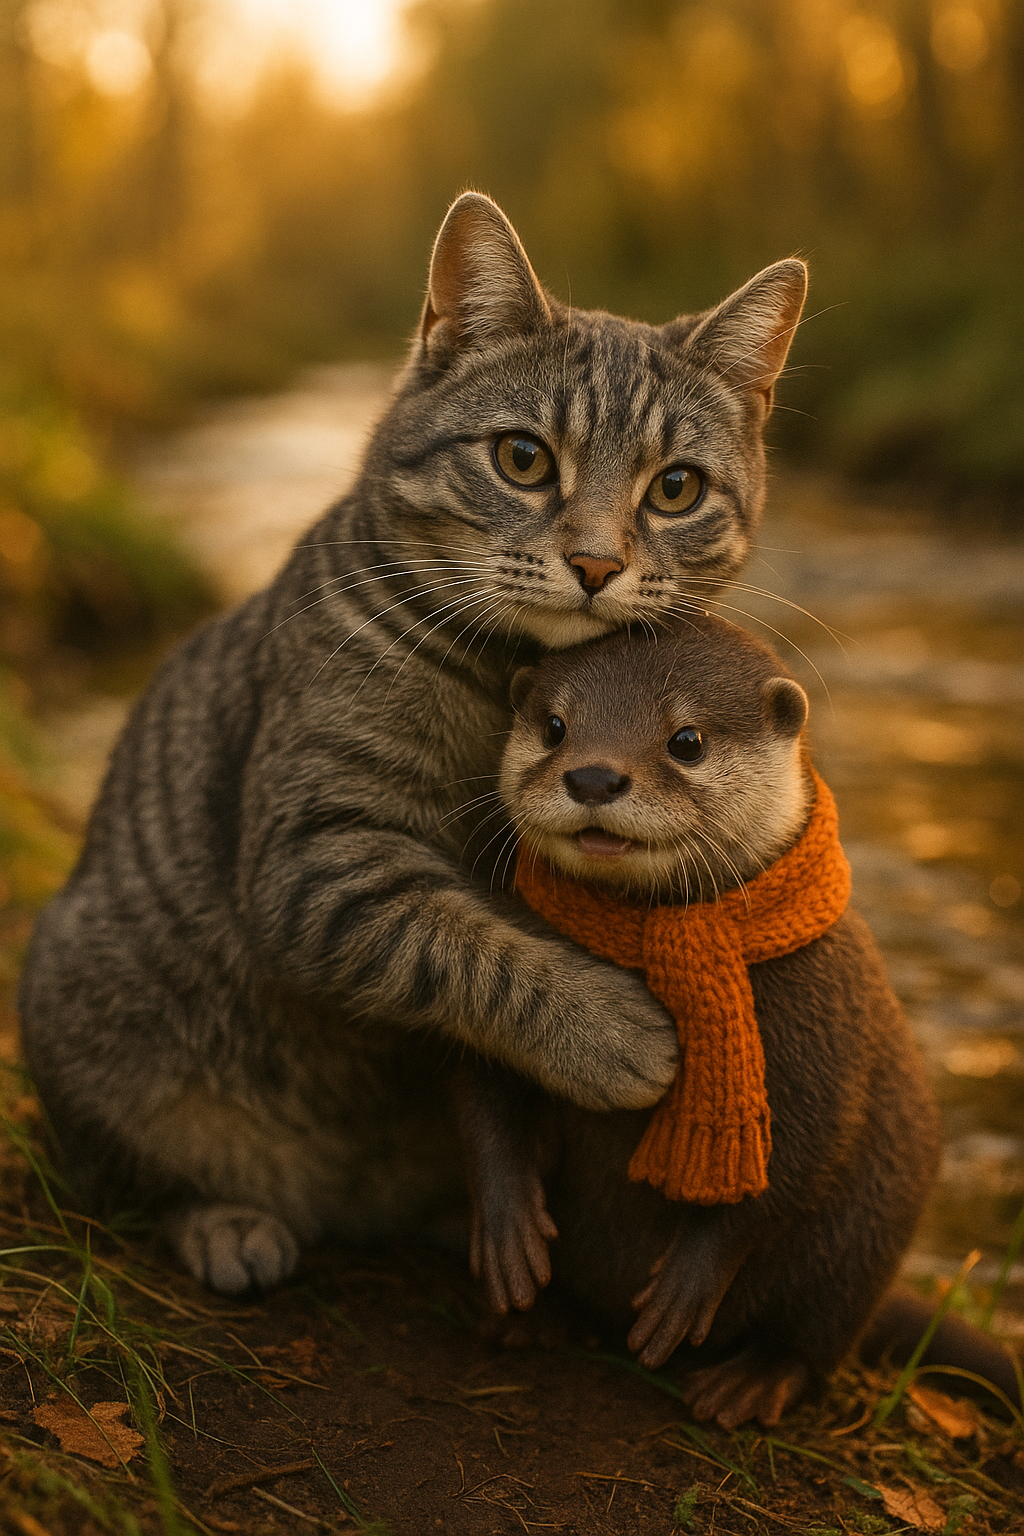

In [21]:
case_number = 34

prompt = use_cases[case_number]

image = generate_image(
    prompt=prompt,
    filename=f"use_case_{case_number}.png"
)

In [23]:
# case_number = 1

# prompt = use_cases[case_number]

# image = generate_image(
#     prompt=prompt,
#     filename=f"use_case_{case_number}.png"
# )

---

## **Text to speech**

In [26]:
from openai import OpenAI
client = OpenAI(api_key=openai.api_key)

# https://platform.openai.com/docs/guides/text-to-speech
response = client.audio.speech.create(
    model="tts-1",
    voice="alloy",
    input="Today is a wonderful day to build something people love!"
)

response.stream_to_file("output.mp3")

/var/folders/5g/9xpg7d6d4114s98tv10y9rgm0000gn/T/ipykernel_21019/3388083089.py:11: DeprecationWarning: Due to a bug, this method doesn't actually stream the response content, `.with_streaming_response.method()` should be used instead
  response.stream_to_file("output.mp3")


In [27]:
# Play the output.mp3 file in the output

from IPython.display import Audio

# Play the audio file
Audio("output.mp3")

In [28]:
# from pathlib import Path
from openai import OpenAI

client = OpenAI()
speech_file_path = "speech.mp3"

with client.audio.speech.with_streaming_response.create(
    model="gpt-4o-mini-tts",
    voice="coral",
    input="Today is a wonderful day to build something people love!",
    instructions="Speak in a cheerful and positive tone.",
) as response:
    response.stream_to_file(speech_file_path)

In [29]:
# Play the speech.mp3 file in the output

from IPython.display import Audio

# Play the audio file
Audio("speech.mp3")

In [31]:
from pathlib import Path
from openai import OpenAI

client = OpenAI()
speech_file_path = "speech.mp3"

with client.audio.speech.with_streaming_response.create(
    model="gpt-4o-mini-tts",
    voice="coral",
    input="Today is a wonderful day to build something people love!",
    instructions="Speak in a sad and demotivated tone.",
) as response:
    response.stream_to_file(speech_file_path)

# Play the speech.mp3 file in the output

from IPython.display import Audio

# Play the audio file
Audio("speech.mp3")

# Speech to Text

In [32]:
# https://platform.openai.com/docs/guides/speech-to-text

from openai import OpenAI
client = OpenAI()

audio_file= open("speech.mp3", "rb")

transcription = client.audio.transcriptions.create(
    model="gpt-4o-transcribe",
    file=audio_file
)

print(transcription.text)

Today is a wonderful day to build something people love.


In [33]:
# https://platform.openai.com/docs/guides/speech-to-text
from openai import OpenAI

client = OpenAI()
audio_file= open("Monster Manor by Sora 2.mp4", "rb")

transcription = client.audio.transcriptions.create(
    model="gpt-4o-transcribe",
    file=audio_file
)

print(transcription.text)

In a small town outside Candycorn Village, in the cul-de-sac at the end of Pumpkin Patch Lane, lies a home of retired ghouls, ghosts, and goblins in Monster Manor. Okay, everyone, gather around. Tonight's the night. Halloween is obviously our biggest night. Everyone comes for candy, we smile, we wave, but we do not show off our magic. No one can know about our special powers. I'd like to give a big spooky shout out to Werewolf for decorating the house. And another spooky shout out to Frankenstein for making sure we have our correct costumes. I love Halloween. On other days, people run away from me. But on Halloween, everyone is very nice. Remember, it is kosher to wear our costumes today, but we still have to hide our secret powers and special tricks. I'm looking at you, Jack-O-Lantern. I've got hella powers, but witch says we're not allowed to show anyone or we'll freak them out. And of course, a spooky shout out to Count Dracula for picking up our Halloween candy. Okay, so the thing 

In [34]:
# /content/RG.mp4

# https://platform.openai.com/docs/guides/speech-to-text
from openai import OpenAI

client = OpenAI()
audio_file= open("RG.mp4", "rb")

transcription = client.audio.transcriptions.create(
    model="gpt-4o-transcribe",
    file=audio_file
)

print(transcription.text)

देखिए, आदमी में दम होना चाहिए, अगर कुछ करना है तो आदमी में दम होना चाहिए, वो अमरीका का राष्टपती है, उसने पचास बार हिंदुस्तान के प्रधान मंतरी का अपमान किया है, पचास बार, पचास बार उसने कहा है कि नरेंदर मोदी को मैंने एक फोन कॉल मारा और उससे कहा कि ओपरेशन सिंदूर बंद करो और दो दिन के अंदर नरेंदर मोदी ने सर जुका कर ओपरेशन सिंदूर बंद कर दिया, ये अमरीका का राष्टपती बोल रहा है, अमरीका का राष्टपती ने बोला है कि साथ हवाई जास गिरे हैं और नरेंदर मोदी में इतना दम नहीं है, इतना दम नहीं है कि वो एक बार बोल दे कि अमरीका का राष्टपती जूट बोल रहा है, इतना दम नहीं है उसमें और छुप रहा है, उसको अमरीका जाना था, अमरीका में डॉनल्ड ट्रॉम्प से मिलना था, मगर डर गए हैं, वो जान ही नहीं रहा है और इधर वोट चोरी कर रहे हैं, 24 घंटा, वोट चोरी क्यों करते हैं, महराश्ट्रा में वोट चोरी क्यों की, हरियाना में वोट चोरी क्यों की, क्योंकि वो आपकी आवास से डरते हैं, बिहार की जनता, हरियाना की जनता, महराश्ट्रा की जनता की आवास से डरते हैं, ये सचाई है, आप देखिये, 1971 के युद में, आप याद रखिये, जो यहां पे बुजुर्ग लोग हैं, 1971 में, बांग

In [37]:
text = "देखिए आद्मी में दम होना चाहिए अगर कुछ करना है तो आद्मी में दम होना चाहिए वो अमरीका का राष्टरपती है उसने पचास बार हिंदुस्तान के प्रधान मंतरी का अपमान किया है पचास बार पचास बार उसने कहा है कि नरेंदर मोधी को मैंने एक फोन कॉल मारा और उससे कहा कि ओपरेशन सिंधूर बंद करो और दो दिन के अंदर नरेंदर मोधी ने सर जुका कर ओपरेशन सिंधूर बंद कर दिया यह अमरीका का राष्टरपती बोल रहा है अमरीका का राष्टरपती ने बोला है कि साथ हवाई जास गिरे हैं और नरेंदर मोधी में इतना दम नहीं है इतना दम नहीं है कि वो एक बार बोल दे कि अमरीका का राष्टरपती जूट बोल रहा है इतना दम नहीं है उसमें और छुप रहा है उसको अमरीका जाना था अमरीका में डॉनल्ड ट्रॉम्प से मिलना था मगर डर गये हैं वो जान ही नहीं वहाँ और इधर वोट चोरी कर रहे हैं चोबिस घंटा वोट चोरी क्यों करते हैं महराश्ट्रा में वोट चोरी क्यों की हरियाना में वोट चोरी क्यों की क्योंके वो आपकी हवास से डरते हैं बिहार की जनता हरियाना की जनता महराश्ट्रा की जनता की हवास से डरते हैं यह सच्चाई है आप देखिए 1971 के यूद में आप याद रखिए जो यहां पे बुजुर्ग लोग हैं 1971 में बांगला देश लड़ाई में अमरीका ने अपना एरक्राफ्ट कैरियर भेजा सेवन्थ फ्लीट थी उनकी उन्होंने अपनी नेवी भेजी हिंदुस्तान को धंगाने के लिए डराने के लिए इंद्रा गांधी जी प्रधान मंतरी थी उन्होंने का आपकी नेवी से हम नहीं डरते हैं आपको जो करना है करो हमें जो करना है हम करेंगे ऐसे प्रधान मंतरी होते हैं वो महिला थी इंद्रा गांधी जी महिला थी मगर इस मर्द से जादा दम उस महिला में थी नरेंदर मोदी जी डरपोक है मैं आपको बता रहा हूँ ना उनका विजिन है ना वो अमरीका के राष्टोपती के सामने खड़े हो सकते हैं यह सचाई है और मैं चेलन्ज देता हूँ कि नरेंदर मोदी में अगर दम है तो बिहार में मीटिंग कर रहे है किसी भी मीटिंग में कह दे कि अमरीका का राष्टोपती जूट बोल रहा है मैं इसके सामने नहीं जुका मैंने ओपरेशन सिंदूर नहीं रुकवाया मैं चेलन्ज करता हूँ कि नरेंदर मोदी जी बिहार के युवाओं को यह कह दे नहीं कर सकते हैं और उल्टा वोट चोरी करके अम्बेटकर जी के सम्भिधान को रत करने में लगे हुए हैं आपको याद होगा इन्होंने कहा 405 सम्भिधान को खतम कर देंगे वोट चोरी के बाद वोट चोरी के बाद यह बाल बाल निकले बाल बाल चुनाओं जीते और अगर वोट चोरी नहीं की होती मैं आपको बता रहा हूँ इंडिया गडबंदन की सरकार आज हिंदुस्तान में राज कर रही होती भाई और बेहनों यह सम्भिधान आपका है यह कोई नई किताब नहीं है इसमें आपकी आवास है हजारों साल पुरानी आवास है इसमें हिंदुस्तान के जो महापुर्श हैं अम्बेटकर जी, गांधी जी, बुत बगवान, नरायन गुरु, फूले जी इनकी आवास है इसको ये खतम करना चाते हैं आरेसेस के लोग और नरेंदर मोदी जी सम्भिधान नहीं चाते हैं वो इसको खतम करना चाते हैं हिंदुस्तान के सारी के सारी संस्तायं जो हैं वो आपसे छीनना चाते हैं और वो वही समय लाना चाते हैं जो पहले था आजादी से पहले जो जहां कोई एलेक्शन नहीं होते थे राजा महराजा निर्णे लेते थे जो करना चाते थे करते थे उनको किसी की जमीन अच्छी लगी तो जमीन ले ली वैसा हिंदुस्तान चाते हैं यह सारा का सारा धाचा जो है चाहे लोकतंत्र हो, चाहे हस्पताल हो, चाहे युनिवर्सिटीज कॉलेजेज हो यह इस सम्भिधान की देन है, इसके बिना यह कुछ नहीं होता इसके बिना यह होई नहीं सकता था और यह अब अम्बेटकर जी के सम्भिधान को खतम करने में लगे हैं और बिहार की जनता को साफ कहे देना चाहिए कि इस सम्भिधान को हम नहीं छूने देंगे भाईयो और बेहनों मैं चाहता हूँ और मैं आपको कह रहा हूँ यहां गटबंदन की सरकार बनेगी और जो नालंदा में पहले शिक्षा का सिस्टम था जो पूरी दुनिया में मशूर था मैं आपको गैरेंटी दे रहा हूँ बिहार की सरकार तो करेगी करेगी मगर जिस दिन इंडिया गटबंदन की सरकार हिंदुस्तान में बनेगी उस दिन मैं आपको कह रहा हूँ गैरेंटी करके मैं गैरेंटी करके कह रहा हूँ दुनिया की सबसे बहतर युनिवर्सिटी यहां इस शहर में बनेगी और हमें चिन बनाएंगे पूरी दुनिया के लिए कि बिहार शिक्षा का सेंटर है नालंदा शिक्षा का सेंटर था और एक बार फिर नालंदा शिक्षा का और रोजगार का सेंटर बनेगा गटबंदन इस काम को पूरा करने की कोशिश करेगा बिहार में और जब दिल्ली में सरकार बनेगी पूरा का पूरा दम लगा कर हम यहाँ पे दुनिया की सबसे बहतर युनिवर्सिटी बिहार को मेसेश देने के लिए दुनिया को मेसेश देने के लिए हिंदुस्तान के बाकी प्रदेशों को मेसेश देने के लिए कि बिहारी मस्दूर नहीं है बिहार शिक्षा का सेंटर है रोजगार का सेंटर है कुछ दिन पहले मैं आपके स्टूडन्ट से मिला दिल्ली में पढ़ाई करते हैं इतने होशियार इतने इंटेलिजन इतनी एनरजी थी उनमें समच थी बिहार में वोट अदिकार यात्रा में मैं घूमा बीस दिन घूमा आप राजनीती को अगर दूसरे प्रदेशों को पाँच दस मिन्त लगते हैं आपको सेकंड लगते हैं बात समझने में आपकी समझ बहुत गहरी है आप में कोई कमी नहीं है बस आपकी सरकार आपके लिए काम नहीं करती है आपकी आवाज नहीं सुनती है और आपके साथ मिलकर बिहार को बनाने का काम नहीं करती है गटबंदन की सरकार बनेगी और मैं आपको एक और गैरेंटी देता हूँ जो गटबंदन दे रहा है महा गटबंदन की गैरेंटी है कि जो सरकार बनेगी बिहार में वो हर जात की सरकार होगी हर धर्म की सरकार होगी उसमें अति पिछडा, पिछडा, डलत, महा डलत, अपसंक्यक, गरीब जेनरल कास्ट, किसान, मस्दूर, सारे के साहें उस सरकार, उनकी आवाज उस सरकार में शामिल होगी, यह मैं गैरिंटी आपको दे रहा हूं क्योंकि बिहार को बिहार की सरकार की जरुवत है बिहार को हर जात, हर धर्म की सरकार की जरुवत है जैसे मैंने यात्रा में कहा, चार हजार किलोमेटर चला और यात्रा में कहा नफरत के बाजार में महबबद की दुकान खोलनी है नफरत से प्रदेश ये देश आगे नहीं जा सकता है नफरत से किसान को, मस्दूर को, युवाँ को कोई फायदा नहीं होता नफरत से नरेंदर मोदी और अमित शाह जैसे लोगों को फायदा होता है, इसके वो फैलाते हैं मगर बिहार की जन्ता को नफरत से फायदा नहीं होता महबबद से फायदा होता है, भाईचारे से फायदा होता है वैसी सरकार हम चलाएंगे आप सब दूर दूर से आए दिल से मैं आपका धन्यवाद करता हूं और एक बात फिर कहना चाहता हूं कि सम्भिधान की रक्षा करनी है यह जो वोट चोरी करने की कोशिश कर रहे हैं बिहार के हर युवा को यह वोट चोरी रोकनी चाहिए पोलिंग बूत पे आप ध्यान से रहिए एलेक्शन डे पे आप ध्यान से रहिए क्योंकि यह वोट चोर है बीजेपी के लोग, आरेसेस के लोग सम्भिधान को नहीं मानते हैं यह वोट चोरी करने की कोशिश करेंगे जैसे इन्हें हरियाना में, महराश्ट्रा में वोट चोरी की यहां भी यह वोट चोरी करने की कोशिश करेंगे आपको और हमको यह रोकना है धन्यवाद जैहिंद, नमस्काद"

from openai import OpenAI
client = OpenAI()

completion = client.chat.completions.create(
                          model="gpt-4o",
                          messages=[
                            {"role": "system", "content": "You are a language translation assistant who can translate text from Hindi to English without losing the original meaning and context. You should provide a clear and accurate translation, maintaining the tone and intent of the original text."},
                            {"role": "user", "content": text}
  ])
# print(completion)
print(completion.choices[0].message.content)

Listen, a person should have the courage. If someone wants to achieve something, they need to have that courage. The President of America has insulted India's Prime Minister fifty times. Fifty times, he has said that he called Narendra Modi and directed him to stop Operation Sindoor, and within two days, Modi bowed down and halted the operation. This is according to the President of America. He also stated that seven aircraft were downed, and Narendra Modi didn't have the guts to say that the American President is lying. Instead, he hid, and he's even hesitant to go to America to meet Donald Trump. Meanwhile, they're busy stealing votes. Why do they steal votes 24/7? Whether it's in Maharashtra or Haryana, they steal votes because they fear your voice - the voice of the people in Bihar, Haryana, and Maharashtra.

Remember the 1971 war? Our elders will recall that during the Bangladesh conflict, America sent its Seventh Fleet to intimidate India. But Prime Minister Indira Gandhi wasn't 

# Describe an image?

In [42]:
# /content/pic.jpeg

import base64 # Used to convert images into text format


# Read and encode the image
with open("dd1.jpeg", "rb") as f:
    base64_image = base64.b64encode(f.read()).decode("utf-8")

response = client.chat.completions.create(
    model="gpt-4.1",
    messages=[
        {
            "role": "user",
            "content": [
                {"type": "text", "text": "show me where I can buy the t-shirt the boy is wearing? Search walmart.com for a matching tShirt."},
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/jpeg;base64,{base64_image}"
                    }
                }
            ]
        }
    ],
)

print(response.choices[0].message.content)


The boy is wearing a brightly colored t-shirt with what seems to be a vibrant, possibly dinosaur or animal-themed graphic design.

### Here’s how you can search for a similar t-shirt on [Walmart.com](https://www.walmart.com):

#### Suggested Search Text:
- **"Kids dinosaur graphic t-shirt"**
- **"Boys animal print t-shirt"**
- **"Boys colorful cartoon t-shirt"**

#### Example Items You May Find:
Below are some direct Walmart links for similar t-shirts:
1. [Dinosaur Boys' T-Shirts at Walmart](https://www.walmart.com/search/?query=dinosaur%20boys%20t-shirt)
2. [Animal Graphic Boys' T-Shirts at Walmart](https://www.walmart.com/search/?query=animal%20boys%20t-shirt)
3. [Colorful Kids T-Shirts](https://www.walmart.com/search/?query=colorful%20boys%20t-shirt)

You can browse these pages for **graphic tees** with bright colors or specific designs that match the boy’s shirt style.

Would you like help narrowing the search to a specific design or help with any other clothing stores?


In [ ]:
# /content/pic.jpeg

import base64 # Used to convert images into text format


# Read and encode the image
with open("dd1.jpeg", "rb") as f:
    base64_image = base64.b64encode(f.read()).decode("utf-8")

response = client.chat.completions.create(
    model="gpt-4.1",
    messages=[
        {
            "role": "user",
            "content": [
                {"type": "text", "text": "Describe this image in detail."},
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/jpeg;base64,{base64_image}"
                    }
                }
            ]
        }
    ],
)

print(response.choices[0].message.content)


In [39]:
# /content/pic.jpeg

import base64 # Used to convert images into text format


# Read and encode the image
with open("dd1.jpeg", "rb") as f:
    base64_image = base64.b64encode(f.read()).decode("utf-8")

response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "user",
            "content": [
                {"type": "text", "text": "What's in this image and which location is this photo taken?"},
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/jpeg;base64,{base64_image}"
                    }
                }
            ]
        }
    ],
)

print(response.choices[0].message.content)


The image shows a young boy standing next to a red car, giving a thumbs-up gesture. The car is parked on a paved area, with some greenery and hills in the background. The sky is overcast and appears foggy or misty, indicating a possibly hilly or mountainous location.

However, based on just this image, it is not possible to definitively identify the exact location where this photo was taken. The setting suggests a natural, possibly hilly area with vegetation, but no specific landmarks or signs are visible to pinpoint the location.


In [40]:
# /content/pic.jpeg

import base64 # Used to convert images into text format


# Read and encode the image
with open("dd3.jpeg", "rb") as f:
    base64_image = base64.b64encode(f.read()).decode("utf-8")

response = client.chat.completions.create(
    model="gpt-4.1",
    messages=[
        {
            "role": "user",
            "content": [
                {"type": "text", "text": "What's in this image and which location is this photo taken?"},
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/jpeg;base64,{base64_image}"
                    }
                }
            ]
        }
    ],
)

print(response.choices[0].message.content)


This image shows a person standing by a waterfront, looking at a historic wooden covered bridge adorned with flowers. The structure in the background is the Kapellbrücke (Chapel Bridge) along with the Wasserturm (Water Tower), which are iconic landmarks in Lucerne, Switzerland. The scene captures the Reuss River and the medieval ambiance of the area, which is one of Switzerland's most famous and picturesque spots.


In [ ]:
# /content/pic.jpeg

import base64 # Used to convert images into text format


# Read and encode the image
with open("dd3.jpeg", "rb") as f:
    base64_image = base64.b64encode(f.read()).decode("utf-8")

response = client.chat.completions.create(
    model="gpt-4.1-mini",
    messages=[
        {
            "role": "user",
            "content": [
                {"type": "text", "text": "how many animals do you see in this photo?"},
                {
                    "type": "image_url",
                    "image_url": {
                        "url": f"data:image/jpeg;base64,{base64_image}"
                    }
                }
            ]
        }
    ],
)

print(response.choices[0].message.content)


In the photo, I see two animals swimming in the water. They appear to be ducks.


In [43]:
# Prompting Techniques

In [44]:
# Imagine you walk into a restaurant and tell the waiter:
#     “Bring me food.”
# “What do you think the waiter will bring you?”

# But if you say:
#     “Please get me a medium-rare grilled paneer steak, no onions, extra lemon on the side, served hot with garlic naan and Coke Zero.”
# The waiter knows exactly what to do.

In [45]:
# The Genie in a Lamp

# If you say:
#     “Make me rich.”
# The genie might drop a gold coin on your lap. Technically — wish granted.

# But if you say:
#     “Make me the richest man in the city, owning 10 unicorn companies by 2028, with ethical success.”
# The genie will get to work — with clarity.

In [46]:
# Talking to a 1000-Intern Superbrain

# Imagine you’re the manager of 1000 super-smart interns, all trained in every topic in the world…
#  But they sit idle unless you give them clear instructions.
# If you say:
#   “Do a market report.”
#  You’ll get 1000 random reports.
# But if you say:
#   “Analyze smartphone market growth in India post-COVID, compare top 3 brands, and recommend ad strategies for GenZ.”
# Boom — they deliver gold.

In [47]:
# Prompting is how you manage intelligence at scale.

# What is Prompt Engineering?
# Prompt Engineering is the process of designing and refining inputs (called prompts) given to Large Language Models (LLMs) like ChatGPT, to get the most accurate, relevant, and useful output possible.

# Why is it important?
# - LLMs are context-driven: The quality of your output heavily depends on the input you give.
# - Inaccurate prompts can lead to vague, hallucinated, or irrelevant outputs.
# - Good prompts reduce trial-and-error, saving time, effort, and API costs.
# - It is critical in enterprise use cases like document summarization, coding assistants, chatbots, customer support, etc.

In [48]:
# What is a Prompt?
# A prompt is the input or question you give to an LLM to generate a response.

# Examples:
# - "Summarize this email."
# - "Write a 100-word paragraph about climate change in a positive tone."
# - "Generate Python code to read a CSV file and plot a bar chart."

In [49]:
# Ideal Structure of a Prompt
# A well-crafted prompt typically includes:

# 1. Role/Instruction: Who is the AI or what it should do

# 2. Context: Background or necessary information

# 3. Task: The actual request to perform.

# 4. Format: Expected output format (optional but powerful).

# 5. Constraints: Rules like word limits, tone, target audience, etc.

# Template:
#     You are a [ROLE]. Given the following [CONTEXT], your task is to [TASK]. Provide the output in [FORMAT] and follow these [CONSTRAINTS].


In [50]:
# Prompt Ladder:

# Prompt 1 – Basic
#     Write something about climate change.

# Prompt 2 – Add Specific Task
#     Write a short paragraph explaining climate change to a 10-year-old.

# Prompt 3 – Add Role and Context
#     You are a science teacher. Explain climate change to a 10-year-old in a fun and simple way.

# Prompt 4 – Add Format and Constraints
#     You are a science teacher. Your job is to explain climate change to a 10-year-old using simple words and no technical jargon. Write a 4–5 sentence story that includes a fun example.

# Prompt 5 – Ideal Version
#     You are a friendly science teacher. Explain climate change to a 10-year-old using a fun story. Use simple words, avoid technical terms, and limit your response to 5 sentences. Include one analogy a child can relate to, like melting ice cream.

---
# Prompt Engineering

Prompt engineering is the practice of designing inputs to LLMs to consistently produce the outputs you need.

It is not a workaround. It is a core engineering discipline. A well-engineered prompt can often outperform a fine-tuned model — at a fraction of the cost.

We will cover 5 patterns, each with a Walmart business use case.


## Zero-Shot Prompting

Ask the model to perform a task with no examples. Works well when:
- The task is common in the model's training data
- The output format is simple

**Walmart use case:** Classify the urgency of a customer support ticket.


In [52]:
# Zero-Shot Prompting
def zero_shot_classify(complaint: str) -> str:
    """Classify complaint severity with no examples — pure zero-shot."""
    response = client.chat.completions.create(
        model="gpt-4o",
        messages=[
            {
                "role": "system",
                "content": (
                    "You are a Walmart customer support triage system. "
                    "Classify each complaint as CRITICAL, HIGH, MEDIUM, or LOW severity. "
                    "Reply with exactly one word: the severity level."
                )
            },
            {"role": "user", "content": f"Complaint: {complaint}"}
        ],
        temperature=0,
        max_tokens=10,
    )
    return response.choices[0].message.content.strip()

complaints = [
    "My item arrived damaged and I need a replacement immediately.",
    "Website was slow this morning but seems fine now.",
    "I was charged twice for the same order — my bank is disputing it.",
    "The packaging could be more eco-friendly.",
    "I can't log into my Walmart+ account and my groceries won't deliver.",
]

print("Zero-Shot Complaint Classification:")
print("-" * 65)
for c in complaints:
    severity = zero_shot_classify(c)
    emoji = {"CRITICAL": "🔴", "HIGH": "🟠", "MEDIUM": "🟡", "LOW": "🟢"}.get(severity, "⚪")
    print(f"{emoji} {severity:<10} | {c[:55]}")


Zero-Shot Complaint Classification:
-----------------------------------------------------------------
🟠 HIGH       | My item arrived damaged and I need a replacement immedi
🟢 LOW        | Website was slow this morning but seems fine now.
🟠 HIGH       | I was charged twice for the same order — my bank is dis
🟢 LOW        | The packaging could be more eco-friendly.
🟠 HIGH       | I can't log into my Walmart+ account and my groceries w


## Few-Shot Prompting

Provide examples of input → output pairs before the actual task. The model learns the pattern from your examples.

**When to use over zero-shot:**
- You need a specific output format
- The task has domain-specific nuances the model might not know
- Zero-shot gives inconsistent results

**Walmart use case:** Extract structured data from unstructured customer feedback.


In [53]:
# Few-Shot Prompting
def few_shot_extract(feedback: str) -> dict:
    """Extract structured data from feedback using few-shot examples."""
    
    few_shot_prompt = """Extract product information from customer feedback.
Return a JSON object with keys: product_name, sentiment (positive/negative/neutral), issue (or null), rating_implied (1-5).
Return ONLY valid JSON. Do not include markdown or extra text.

Example 1:
Feedback: "The Great Value coffee maker stopped working after 3 weeks. Very disappointing."
Output: {{"product_name": "Great Value coffee maker", "sentiment": "negative", "issue": "stopped working after 3 weeks", "rating_implied": 1}}

Example 2:
Feedback: "Absolutely love my new Onn. TV! Picture quality is stunning and setup was easy."
Output: {{"product_name": "Onn. TV", "sentiment": "positive", "issue": null, "rating_implied": 5}}

Example 3:
Feedback: "The Sam's Choice pasta is decent. Nothing special but good value for the price."
Output: {{"product_name": "Sam's Choice pasta", "sentiment": "neutral", "issue": null, "rating_implied": 3}}

Now extract from:
Feedback: "{feedback}"
Output:"""

    response = client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[{"role": "user", "content": few_shot_prompt.format(feedback=feedback)}],
        response_format={"type": "json_object"},
        temperature=0,
        max_tokens=120,
    )
    
    raw = response.choices[0].message.content.strip()
    return json.loads(raw)

feedbacks = [
    "The Equate pain relief tablets work great — I use them every day and they're half the price of brand name.",
    "My Walmart+ order was 2 hours late and the frozen food was partially thawed. Very frustrated.",
    "George men's jeans fit perfectly and the material feels durable. Will buy again.",
]

print("Few-Shot Structured Extraction:")
print("=" * 65)
for fb in feedbacks:
    result = few_shot_extract(fb)
    print(f"\nFeedback: {fb[:60]}...")
    print(f"Extracted: {json.dumps(result, indent=2)}")

Few-Shot Structured Extraction:

Feedback: The Equate pain relief tablets work great — I use them every...
Extracted: {
  "product_name": "Equate pain relief tablets",
  "sentiment": "positive",
  "issue": null,
  "rating_implied": 5
}

Feedback: My Walmart+ order was 2 hours late and the frozen food was p...
Extracted: {
  "product_name": "Walmart+",
  "sentiment": "negative",
  "issue": "order was 2 hours late and the frozen food was partially thawed",
  "rating_implied": 1
}

Feedback: George men's jeans fit perfectly and the material feels dura...
Extracted: {
  "product_name": "George men's jeans",
  "sentiment": "positive",
  "issue": null,
  "rating_implied": 5
}


## Chain-of-Thought (CoT) Prompting

Tell the model to **think step by step** before giving a final answer. This forces the model to reason through multi-step problems rather than pattern-match to the nearest answer.

**When to use:**
- Multi-step reasoning (math, logic, planning)
- Decisions that require considering multiple factors
- Any situation where you'd want a human to "show their work"

**Walmart use case:** Supply chain reorder decision with multiple constraints.


In [55]:
# https://arxiv.org/pdf/2201.11903

# Without CoT
# Prompt: What is the area of a rectangle with length 10 and width 5?
# Answer: 50

# With CoT
# Prompt: What is the area of a rectangle with length 10 and width 5? Show your reasoning step by step.
# Answer:
# Given the length of the rectangle is 10.
# Given the width of the rectangle is 5.
# The formula for the area of a rectangle is: Area = Length × Width
# Substituting the given values: Area = 10 × 5
# Calculating the multiplication: Area = 50
# Therefore, the area of the rectangle is 50.

In [56]:
# Chain-of-Thought Prompting

# ── WITHOUT Chain-of-Thought ──
no_cot_response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {"role": "user", "content": """
A Walmart distribution center has the following situation:
- Current stock of Product X: 800 units
- Average daily demand: 65 units/day
- Lead time to restock: 8 days
- Safety stock required: 4 days of demand
- Upcoming promotional event in 5 days expected to triple demand for 3 days

Should we place a reorder today? Answer yes or no.
"""}
    ],
    temperature=0,
    max_tokens=20,
)
print("WITHOUT Chain-of-Thought:")
print(f"  Answer: {no_cot_response.choices[0].message.content.strip()}\n")

# ── WITH Chain-of-Thought ──
cot_response = client.chat.completions.create(
    model="gpt-4o-mini",
    messages=[
        {"role": "user", "content": """
A Walmart distribution center has the following situation:
- Current stock of Product X: 800 units
- Average daily demand: 65 units/day
- Lead time to restock: 8 days
- Safety stock required: 4 days of demand
- Upcoming promotional event in 5 days expected to triple demand for 3 days

Should we place a reorder today? Think step by step, calculate each quantity explicitly, then give a final recommendation with justification.
"""}
    ],
    temperature=0,
    max_tokens=400,
)
print("WITH Chain-of-Thought:")
print(cot_response.choices[0].message.content.strip())


WITHOUT Chain-of-Thought:
  Answer: To determine whether to place a reorder today, we need to calculate the stock situation considering the upcoming promotional

WITH Chain-of-Thought:
To determine whether to place a reorder today for Product X at the Walmart distribution center, we need to analyze the current stock, demand, lead time, safety stock, and the impact of the upcoming promotional event. Let's break this down step by step.

### Step 1: Calculate the Safety Stock
Safety stock is calculated based on the average daily demand and the number of days of safety stock required.

- **Average daily demand**: 65 units/day
- **Safety stock required**: 4 days of demand

\[
\text{Safety Stock} = \text{Average Daily Demand} \times \text{Safety Stock Days} = 65 \, \text{units/day} \times 4 \, \text{days} = 260 \, \text{units}
\]

### Step 2: Calculate the Reorder Point
The reorder point is the level of inventory at which a new order should be placed to avoid stockouts. It is calculated as t

# Happy Learning